# Đề tài 8 — PCA, SVD và xấp xỉ hạng thấp
## Notebook 3/3 — Phần C: Bài tập

| Bài | Nội dung | Kiểm chứng |
|---|---|---|
| C.1 | Tính tay PCA cho 4 điểm | B.1, B.2 |
| C.2 | PCA trên ma trận hiệp phương sai vs ma trận tương quan | — |
| C.3 | Bổ đề Johnson–Lindenstrauss với $n=1000$ điểm trong $\mathbb R^{10\,000}$ | B.4 |
| C.4 | SVD đầy đủ vs SVD ngẫu nhiên vs lặp lũy thừa trên ma trận $10^4\times10^3$ | A.2, B.5 |

Notebook này import các cài đặt từ `src/pca_core.py` (xuất từ Notebook 1). Riêng hàm lặp lũy thừa khối được định nghĩa tại C.4 vì là một phần của bài tập.

In [1]:
import os, sys, time
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats
from sklearn.datasets import load_wine

for p in ["../src", "src", "."]:                      # tìm thư mục chứa pca_core.py
    if os.path.exists(os.path.join(p, "pca_core.py")):
        sys.path.insert(0, os.path.abspath(p)); break
from pca_core import pca_svd, fix_sign, randomized_svd, make_spectrum_matrix, mean_std

SEED, N_RUNS = 42, 5
plt.rcParams.update({"figure.dpi": 100, "axes.grid": True, "grid.alpha": 0.3})
np.set_printoptions(precision=4, suppress=True)
wine = load_wine()

---
# Phần C — Bài tập

## C.1 Tính tay với bốn điểm $(3,1),(1,3),(-3,-1),(-1,-3)$

**Bước 1 — trung bình.** $\mu=\frac14\big(3+1-3-1,\ 1+3-1-3\big)=(0,0)$: dữ liệu đã quy tâm, $X_c=X=\begin{bmatrix}3&1\\1&3\\-3&-1\\-1&-3\end{bmatrix}$.

**Bước 2 — ma trận tán xạ và hiệp phương sai.**
$X^\top X=\begin{bmatrix}9+1+9+1 & 3+3+3+3\\ 3+3+3+3 & 1+9+1+9\end{bmatrix}=\begin{bmatrix}20&12\\12&20\end{bmatrix}$,
nên $\Sigma=\frac1{n-1}X^\top X=\frac13\begin{bmatrix}20&12\\12&20\end{bmatrix}=\begin{bmatrix}20/3&4\\4&20/3\end{bmatrix}$.
(Nếu dùng ước lượng hợp lý cực đại $\frac1n X^\top X=\begin{bmatrix}5&3\\3&5\end{bmatrix}$ thì mọi trị riêng chia cho 4 thay vì 3; hướng chính và tỉ lệ phương sai không đổi.)

**Bước 3 — trị riêng, vector riêng.** $\det\begin{bmatrix}20/3-\lambda&4\\4&20/3-\lambda\end{bmatrix}=(20/3-\lambda)^2-16=0\Rightarrow\lambda=20/3\pm4$:
$$\lambda_1=\tfrac{32}3\approx10.667,\quad v_1=\tfrac1{\sqrt2}(1,1);\qquad \lambda_2=\tfrac83\approx2.667,\quad v_2=\tfrac1{\sqrt2}(1,-1).$$
(Kiểm tra: $\Sigma v_1=\frac1{\sqrt2}(20/3+4,\ 4+20/3)=\frac{32}3v_1$.)

**Bước 4 — tỉ lệ phương sai giải thích.** $\dfrac{\lambda_1}{\lambda_1+\lambda_2}=\dfrac{32/3}{40/3}=0.8$, $\dfrac{\lambda_2}{\lambda_1+\lambda_2}=0.2$.

**Bước 5 — sai số tái tạo khi giữ 1 thành phần.** Tọa độ trên $v_2$: $\frac{3-1}{\sqrt2}=\sqrt2$, $\frac{1-3}{\sqrt2}=-\sqrt2$, $\frac{-3+1}{\sqrt2}=-\sqrt2$, $\frac{-1+3}{\sqrt2}=\sqrt2$. Phần bị bỏ của mỗi điểm có độ dài bình phương $2$, nên
$$\sum_i\|x_i-v_1v_1^\top x_i\|^2=4\times2=8 .$$
Các điểm tái tạo: $(2,2),(2,2),(-2,-2),(-2,-2)$.

**Bước 6 — kiểm chứng với B.2.** Giá trị kỳ dị của $X$: $\sigma_i^2=(n-1)\lambda_i$, tức $\sigma_1^2=32$, $\sigma_2^2=8$ ($\sigma_1=4\sqrt2$, $\sigma_2=2\sqrt2$). Eckart–Young: $\min_{\operatorname{rank}B\le1}\|X-B\|_F^2=\sigma_2^2=8$ — **khớp với bước 5**. Theo B.1: sai số tái tạo chia $n-1$ là $8/3=\lambda_2=\operatorname{tr}\Sigma-\lambda_1$.

In [2]:
X4 = np.array([[3, 1], [1, 3], [-3, -1], [-1, -3]], dtype=float)
mu4, W4, lam4 = pca_svd(X4, 1)
print("Trung bình:", mu4)
print("Hiệp phương sai:\n", np.cov(X4, rowvar=False))
print("Trị riêng:", lam4, "| 32/3, 8/3 =", 32 / 3, 8 / 3)
print("Hướng chính 1:", fix_sign(W4).ravel(), "| (1,1)/sqrt2 =", np.array([1, 1]) / np.sqrt(2))
print("Tỉ lệ phương sai:", lam4 / lam4.sum())
X4_hat = (X4 - mu4) @ W4 @ W4.T + mu4
print("Điểm tái tạo:\n", X4_hat)
S4 = np.linalg.svd(X4, compute_uv=False)
print(f"Sai số tái tạo = {np.sum((X4 - X4_hat)**2):.6f} | sigma_2^2 = {S4[1]**2:.6f} | sigma^2 = {S4**2}")

Trung bình: [0. 0.]
Hiệp phương sai:
 [[6.6667 4.    ]
 [4.     6.6667]]
Trị riêng: [10.6667  2.6667] | 32/3, 8/3 = 10.666666666666666 2.6666666666666665
Hướng chính 1: [0.7071 0.7071] | (1,1)/sqrt2 = [0.7071 0.7071]
Tỉ lệ phương sai: [0.8 0.2]
Điểm tái tạo:
 [[ 2.  2.]
 [ 2.  2.]
 [-2. -2.]
 [-2. -2.]]
Sai số tái tạo = 8.000000 | sigma_2^2 = 8.000000 | sigma^2 = [32.  8.]


## C.2 PCA trên ma trận hiệp phương sai và trên ma trận tương quan

Dữ liệu Wine có 13 biến với **đơn vị khác nhau** (độ cồn %, magie mg/l, proline mg/l, …). PCA trên **ma trận hiệp phương sai** dùng dữ liệu gốc; PCA trên **ma trận tương quan** $R=D^{-1/2}\Sigma D^{-1/2}$ ($D=\operatorname{diag}\Sigma$) tương đương PCA trên dữ liệu đã chuẩn hóa từng biến về phương sai 1.

Thí nghiệm: (i) so sánh tỉ lệ phương sai và hệ số tải (loadings) của PC1; (ii) **đổi đơn vị** proline từ mg/l sang g/l (chia 1000) — một thay đổi vô nghĩa về mặt vật lý — và xem kết quả nào thay đổi.

Độ lệch chuẩn các biến: [  0.81   1.12   0.27   3.34  14.28   0.63   1.     0.12   0.57   2.32
   0.23   0.71 314.91]

[gốc (proline mg/l)]
  Hiệp phương sai: PC1 giải thích 99.81%; 3 biến tải lớn nhất: [np.str_('proline'), np.str_('magnesium'), np.str_('alcalinity_of_ash')]
  Tương quan     : PC1 giải thích 36.20%; 3 biến tải lớn nhất: [np.str_('flavanoids'), np.str_('total_phenols'), np.str_('od280/od315_of_diluted_wines')]

[proline đổi sang g/l]
  Hiệp phương sai: PC1 giải thích 90.91%; 3 biến tải lớn nhất: [np.str_('magnesium'), np.str_('color_intensity'), np.str_('alcalinity_of_ash')]
  Tương quan     : PC1 giải thích 36.20%; 3 biến tải lớn nhất: [np.str_('flavanoids'), np.str_('total_phenols'), np.str_('od280/od315_of_diluted_wines')]

max |eig(R) - lambda(PCA chuẩn hóa)| = 4.440892098500626e-15


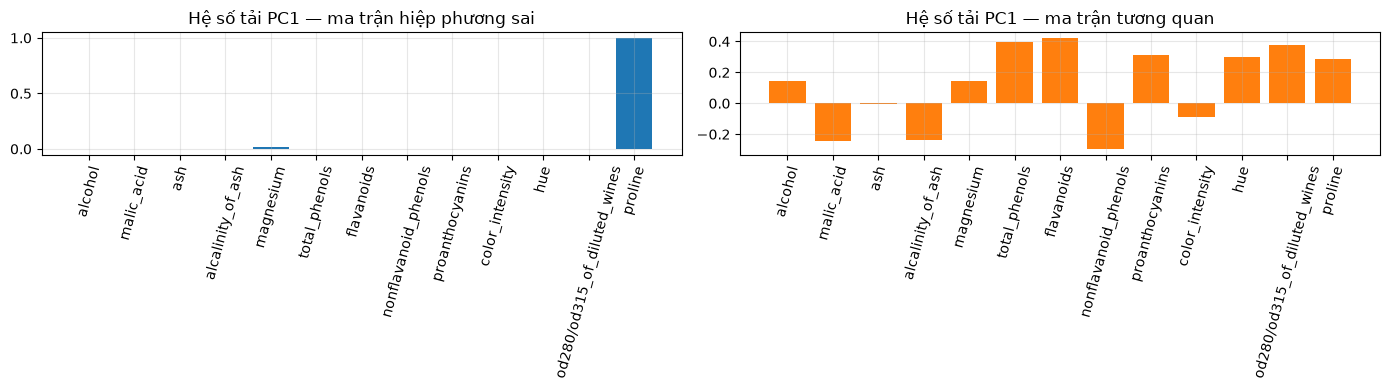

In [3]:
Xraw = wine.data.copy()
names = np.array(wine.feature_names)

def pca_cov(X, k):                  # PCA trên ma trận hiệp phương sai
    return pca_svd(X, k)

def pca_corr(X, k):                 # PCA trên ma trận tương quan = PCA trên dữ liệu chuẩn hóa
    return pca_svd((X - X.mean(0)) / X.std(0, ddof=1), k)

print("Độ lệch chuẩn các biến:", np.round(Xraw.std(0, ddof=1), 2))
for label, X_ in [("gốc (proline mg/l)", Xraw), ("proline đổi sang g/l", Xraw * np.where(names == "proline", 1e-3, 1.0))]:
    _, Wc, lc = pca_cov(X_, 2); _, Wr, lr_ = pca_corr(X_, 2)
    top_c = names[np.argsort(-np.abs(Wc[:, 0]))[:3]]; top_r = names[np.argsort(-np.abs(Wr[:, 0]))[:3]]
    print(f"\n[{label}]")
    print(f"  Hiệp phương sai: PC1 giải thích {lc[0] / lc.sum():.2%}; 3 biến tải lớn nhất: {list(top_c)}")
    print(f"  Tương quan     : PC1 giải thích {lr_[0] / lr_.sum():.2%}; 3 biến tải lớn nhất: {list(top_r)}")

# Kiểm tra: trị riêng của ma trận tương quan = trị riêng PCA trên dữ liệu chuẩn hóa
Rm = np.corrcoef(Xraw, rowvar=False)
print("\nmax |eig(R) - lambda(PCA chuẩn hóa)| =", np.abs(np.sort(np.linalg.eigvalsh(Rm))[::-1] - pca_corr(Xraw, 13)[2]).max())

fig, ax = plt.subplots(1, 2, figsize=(14, 4))
_, Wc, _ = pca_cov(Xraw, 1); _, Wr, _ = pca_corr(Xraw, 1)
ax[0].bar(names, fix_sign(Wc)[:, 0]); ax[0].set_title("Hệ số tải PC1 — ma trận hiệp phương sai")
ax[1].bar(names, fix_sign(Wr)[:, 0], color="tab:orange"); ax[1].set_title("Hệ số tải PC1 — ma trận tương quan")
for a in ax: a.tick_params(axis="x", rotation=75)
plt.tight_layout(); plt.show()

**Nhận xét C.2.**
- Với ma trận hiệp phương sai, PC1 giải thích ~99.8% phương sai và **gần như trùng với trục proline** — chỉ vì proline có số đo lớn nhất (độ lệch chuẩn ~315), không phải vì nó chứa nhiều thông tin.
- Đổi proline sang g/l làm kết quả PCA hiệp phương sai **thay đổi hoàn toàn** (PC1 chuyển sang magie — biến có số lớn tiếp theo). PCA tương quan **bất biến** với phép đổi đơn vị (đổi thang đo từng biến).
- **Quy tắc:** dùng ma trận tương quan (chuẩn hóa) khi các biến khác đơn vị — như đặc trưng rung ở Phần D (RMS theo m/s², độ nhọn không thứ nguyên, năng lượng dải tần theo (m/s²)²). Dùng hiệp phương sai khi các biến cùng đơn vị và độ lớn có ý nghĩa (ví dụ các pixel, hoặc phổ biên độ cùng một trục).

## C.3 Kiểm chứng bổ đề Johnson–Lindenstrauss: $n=1000$ điểm trong $\mathbb R^{10\,000}$

Chiếu $f(x)=Rx/\sqrt k$ với các $k$ khác nhau; với mọi $\binom{1000}2=499\,500$ cặp, tính **tỉ số méo** $\rho=\|f(u)-f(v)\|^2/\|u-v\|^2$. Theo B.4, $k\rho\sim\chi^2_k$ cho mỗi cặp, tức $\rho$ tập trung quanh 1 với độ lệch chuẩn $\sqrt{2/k}$. Lặp 5 ma trận chiếu ngẫu nhiên.

Bình phương khoảng cách mọi cặp tính nhanh bằng ma trận Gram: $\|x_i-x_j\|^2=\|x_i\|^2+\|x_j\|^2-2x_i^\top x_j$.

In [4]:
def pairwise_sq_dists(Y):
    sq = (Y.astype(np.float64)**2).sum(1)
    G = Y.astype(np.float64) @ Y.T.astype(np.float64)
    D = sq[:, None] + sq[None, :] - 2 * G
    iu = np.triu_indices(len(Y), 1)
    return D[iu]

n_pts, dim = 1000, 10_000
rng = np.random.default_rng(SEED)
X_jl = rng.standard_normal((n_pts, dim)).astype(np.float32)     # 1000 điểm trong R^10000
D_orig = pairwise_sq_dists(X_jl)

k_list = [25, 50, 100, 200, 500, 1000, 2000]
eps_list = [0.1, 0.2, 0.3]
k_bound = {e: 4 * np.log(n_pts) / (e**2 / 2 - e**3 / 3) for e in eps_list}
summary = {k: {"max_dev": [], **{e: [] for e in eps_list}} for k in k_list}
rho_example = {}
t0 = time.perf_counter()
for r in range(N_RUNS):
    g = np.random.default_rng(SEED + 100 + r)
    for k in k_list:
        R = g.standard_normal((k, dim)).astype(np.float32)
        Y = X_jl @ R.T / np.sqrt(k)                            # f(x) = R x / sqrt(k)
        rho = pairwise_sq_dists(Y) / D_orig
        summary[k]["max_dev"].append(np.abs(rho - 1).max())
        for e in eps_list:
            summary[k][e].append(np.mean(np.abs(rho - 1) <= e))   # tỉ lệ cặp bảo toàn trong (1 ± eps)
        if r == 0:
            rho_example[k] = rho
print(f"Thời gian: {time.perf_counter() - t0:.1f}s")
print("k tối thiểu theo bổ đề (n = 1000):", {e: int(np.ceil(v)) for e, v in k_bound.items()})
print(f"\n{'k':>5} | {'max |rho-1|':>16} | " + " | ".join(f"tỉ lệ cặp trong 1±{e}" for e in eps_list))
for k in k_list:
    print(f"{k:>5} | {mean_std(summary[k]['max_dev'], '.3f'):>16} | " +
          " | ".join(f"{mean_std(summary[k][e], '.4f'):>19}" for e in eps_list))

Thời gian: 5.1s
k tối thiểu theo bổ đề (n = 1000): {0.1: 5921, 0.2: 1595, 0.3: 768}

    k |      max |rho-1| | tỉ lệ cặp trong 1±0.1 | tỉ lệ cặp trong 1±0.2 | tỉ lệ cặp trong 1±0.3
   25 |    1.882 ± 0.102 |     0.2737 ± 0.0024 |     0.5202 ± 0.0035 |     0.7166 ± 0.0042
   50 |    1.257 ± 0.112 |     0.3829 ± 0.0031 |     0.6865 ± 0.0038 |     0.8720 ± 0.0030
  100 |    0.817 ± 0.078 |     0.5236 ± 0.0095 |     0.8477 ± 0.0082 |     0.9678 ± 0.0027
  200 |    0.545 ± 0.045 |     0.6840 ± 0.0033 |     0.9555 ± 0.0023 |     0.9969 ± 0.0005
  500 |    0.320 ± 0.010 |     0.8845 ± 0.0013 |     0.9982 ± 0.0002 |     1.0000 ± 0.0000
 1000 |    0.226 ± 0.016 |     0.9741 ± 0.0022 |     1.0000 ± 0.0000 |     1.0000 ± 0.0000
 2000 |    0.154 ± 0.006 |     0.9985 ± 0.0002 |     1.0000 ± 0.0000 |     1.0000 ± 0.0000


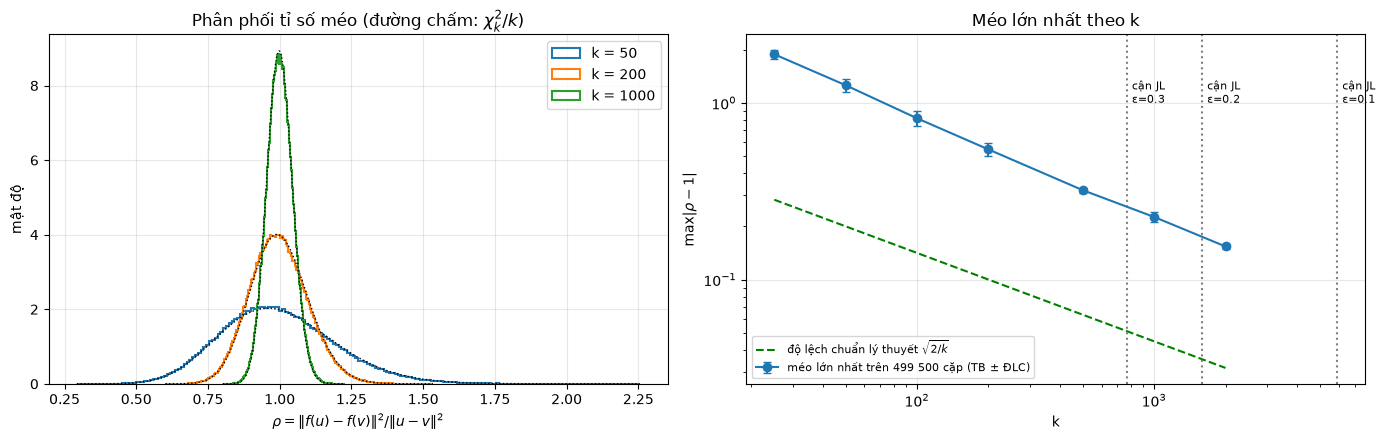

In [5]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for k in [50, 200, 1000]:
    rho = rho_example[k]
    ax[0].hist(rho, bins=200, density=True, histtype="step", lw=1.5, label=f"k = {k}")
    xs = np.linspace(rho.min(), rho.max(), 300)
    ax[0].plot(xs, k * stats.chi2.pdf(k * xs, k), "k:", lw=1)          # mật độ của chi2_k / k
ax[0].set(xlabel=r"$\rho=\|f(u)-f(v)\|^2/\|u-v\|^2$", ylabel="mật độ", title=r"Phân phối tỉ số méo (đường chấm: $\chi^2_k/k$)")
ax[0].legend()

ks = np.array(k_list)
md_mean = np.array([np.mean(summary[k]["max_dev"]) for k in k_list]); md_std = np.array([np.std(summary[k]["max_dev"], ddof=1) for k in k_list])
ax[1].errorbar(ks, md_mean, yerr=md_std, fmt="o-", capsize=3, label="méo lớn nhất trên 499 500 cặp (TB ± ĐLC)")
ax[1].plot(ks, np.sqrt(2 / ks), "g--", label=r"độ lệch chuẩn lý thuyết $\sqrt{2/k}$")
for e in eps_list:
    ax[1].axvline(k_bound[e], ls=":", c="gray"); ax[1].text(k_bound[e] * 1.05, 1.0, f"cận JL\nε={e}", fontsize=8)
ax[1].set(xscale="log", yscale="log", xlabel="k", ylabel=r"$\max|\rho-1|$", title="Méo lớn nhất theo k")
ax[1].legend(fontsize=8)
plt.tight_layout(); plt.show()

**Nhận xét C.3.**
- Phân phối $\rho$ khớp $\chi^2_k/k$ như bước 1 của chứng minh B.4; độ rộng giảm theo $1/\sqrt k$.
- Méo lớn nhất trên mọi cặp giảm theo $k$; ở $k=2000$ (> cận JL cho $\varepsilon=0.2$ là $k\ge1595$) **mọi cặp** đều nằm trong $1\pm0.2$ ở cả 5 lần chạy — xác suất thành công thực tế gần 1, lớn hơn rất nhiều so với $1/n$ của bổ đề (chặn hợp rất bảo thủ).
- Kích thước cần thiết **không phụ thuộc $d=10\,000$**: chiếu xuống 1000–2000 chiều vẫn bảo toàn hình học của 1000 điểm.

## C.4 SVD đầy đủ, SVD ngẫu nhiên và lặp lũy thừa trên ma trận $10^4\times10^3$

Hai ma trận $A=U\operatorname{diag}(\sigma)V^\top$ kích thước $10\,000\times1\,000$ với phổ biết trước:
- **suy giảm nhanh:** $\sigma_i=e^{-(i-1)/10}$;
- **suy giảm chậm:** $\sigma_i=i^{-1/2}$.

Cần $k=20$ thành phần. So sánh:
1. `np.linalg.svd` đầy đủ (dạng gọn);
2. SVD ngẫu nhiên tự cài (A.2) với $q=0,1,2$, $p=10$;
3. **lặp lũy thừa khối** (lặp trực giao / subspace iteration): $Q\leftarrow\operatorname{orth}(A A^\top Q)$, dừng khi các giá trị kỳ dị ước lượng thay đổi tương đối $<10^{-6}$ hoặc sau 200 vòng.

Đo: thời gian (TB ± ĐLC trên 5 lần chạy), sai số phổ tương đối $\|A-\hat A_k\|_2/\sigma_{k+1}$ (tối ưu = 1), sai số Frobenius tương đối so với $\big(\sum_{i>k}\sigma_i^2\big)^{1/2}$, và sai số tương đối lớn nhất của $\hat\sigma_1,\dots,\hat\sigma_k$. Chuẩn phổ của phần dư được ước lượng bằng 50 vòng lặp lũy thừa trên toán tử $x\mapsto(A-\hat A_k)x$ (không tạo ma trận phần dư).

In [6]:
# [CORE]
def block_power_svd(A, k, max_iter=200, tol=1e-6, rng=None):
    # Lặp lũy thừa khối (subspace iteration) cho k thành phần kỳ dị đầu
    rng = np.random.default_rng(rng)
    Q, _ = np.linalg.qr(A @ rng.standard_normal((A.shape[1], k)))
    s_old = np.zeros(k)
    for it in range(max_iter):
        Z, _ = np.linalg.qr(A.T @ Q)              # trực chuẩn hóa ở cả hai phía để ổn định
        Q, Rq = np.linalg.qr(A @ Z)               # Rq = Q^T A Z (k x k)
        s = np.linalg.svd(Rq, compute_uv=False)   # ước lượng rẻ các sigma để kiểm tra hội tụ
        if np.max(np.abs(s - s_old) / s) < tol:
            break
        s_old = s
    Ub, s, Vt = np.linalg.svd(Q.T @ A, full_matrices=False)
    return Q @ Ub, s, Vt, it + 1

In [7]:
def residual_spectral_norm(A, U, S, Vt, n_iter=50, seed=0):
    # ||A - U S Vt||_2 bằng lặp lũy thừa trên toán tử phần dư (không tạo ma trận m x n mới)
    x = np.random.default_rng(seed).standard_normal(A.shape[1])
    for _ in range(n_iter):
        y = A @ x - U @ (S * (Vt @ x))
        x = A.T @ y - Vt.T @ (S * (U.T @ y))
        x /= np.linalg.norm(x)
    y = A @ x - U @ (S * (Vt @ x))
    return np.linalg.norm(y)

m, n, k = 10_000, 1_000, 20
spectra = {"nhanh: exp(-(i-1)/10)": np.exp(-np.arange(n) / 10), "chậm: i^(-1/2)": 1 / np.sqrt(np.arange(1, n + 1))}
methods = ["SVD đầy đủ", "ngẫu nhiên q=0", "ngẫu nhiên q=1", "ngẫu nhiên q=2", "lặp lũy thừa khối"]
results_c4 = {}
t_all = time.perf_counter()
for sname, s in spectra.items():
    rng = np.random.default_rng(SEED)
    A = make_spectrum_matrix(m, n, s, rng)
    opt_F = np.sqrt((s[k:]**2).sum())
    R = {mth: {"time": [], "spec": [], "frob": [], "sv": [], "iters": []} for mth in methods}
    for r in range(N_RUNS):
        for mth in methods:
            t0 = time.perf_counter()
            if mth == "SVD đầy đủ":
                U, S, Vt = np.linalg.svd(A, full_matrices=False); U, S, Vt = U[:, :k], S[:k], Vt[:k]; its = 0
            elif mth.startswith("ngẫu nhiên"):
                U, S, Vt = randomized_svd(A, k, p=10, q=int(mth[-1]), rng=SEED + r); its = 0
            else:
                U, S, Vt, its = block_power_svd(A, k, rng=SEED + r)
            R[mth]["time"].append(time.perf_counter() - t0)
            R[mth]["spec"].append(residual_spectral_norm(A, U, S, Vt) / s[k])
            R[mth]["frob"].append(np.sqrt(max(np.linalg.norm(A, "fro")**2 - (S**2).sum(), 0)) / opt_F)  # ||A-Ak||_F^2 = ||A||^2 - ||Ak||^2 khi U, V trực chuẩn
            R[mth]["sv"].append(np.max(np.abs(S - s[:k]) / s[:k]))
            R[mth]["iters"].append(its)
    results_c4[sname] = R
    del A
print(f"Tổng thời gian C.4: {time.perf_counter() - t_all:.0f}s")

for sname, R in results_c4.items():
    print(f"\n=== Phổ suy giảm {sname} (k = {k}) ===")
    print(f"{'phương pháp':<18} | {'thời gian (s)':>15} | {'||A-Âk||_2/σ_k+1':>18} | {'Frobenius/tối ưu':>18} | {'max sai số σ_i':>18}")
    for mth in methods:
        extra = f"  ({np.mean(R[mth]['iters']):.0f} vòng)" if mth == "lặp lũy thừa khối" else ""
        print(f"{mth:<18} | {mean_std(R[mth]['time'], '.3f'):>15} | {mean_std(R[mth]['spec'], '.4f'):>18} | "
              f"{mean_std(R[mth]['frob'], '.6f'):>18} | {mean_std(R[mth]['sv'], '.2e'):>18}{extra}")

Tổng thời gian C.4: 74s

=== Phổ suy giảm nhanh: exp(-(i-1)/10) (k = 20) ===
phương pháp        |   thời gian (s) |   ||A-Âk||_2/σ_k+1 |   Frobenius/tối ưu |     max sai số σ_i
SVD đầy đủ         |   2.953 ± 0.281 |    1.0000 ± 0.0000 | 1.000000 ± 0.000000 | 2.22e-15 ± 0.00e+00
ngẫu nhiên q=0     |   0.127 ± 0.132 |    1.1905 ± 0.0781 | 1.229319 ± 0.039410 | 5.79e-02 ± 1.80e-02
ngẫu nhiên q=1     |   0.094 ± 0.057 |    1.0000 ± 0.0000 | 1.000372 ± 0.000082 | 5.76e-04 ± 2.26e-04
ngẫu nhiên q=2     |   0.130 ± 0.057 |    1.0000 ± 0.0000 | 1.000003 ± 0.000001 | 6.16e-06 ± 2.36e-06
lặp lũy thừa khối  |   0.807 ± 0.176 |    1.0000 ± 0.0000 | 1.000000 ± 0.000000 | 1.34e-06 ± 1.13e-07  (36 vòng)

=== Phổ suy giảm chậm: i^(-1/2) (k = 20) ===
phương pháp        |   thời gian (s) |   ||A-Âk||_2/σ_k+1 |   Frobenius/tối ưu |     max sai số σ_i
SVD đầy đủ         |   3.513 ± 0.808 |    1.0000 ± 0.0000 | 1.000000 ± 0.000000 | 8.78e-16 ± 1.10e-31
ngẫu nhiên q=0     |   0.128 ± 0.117 |    2.1269 ± 0.2

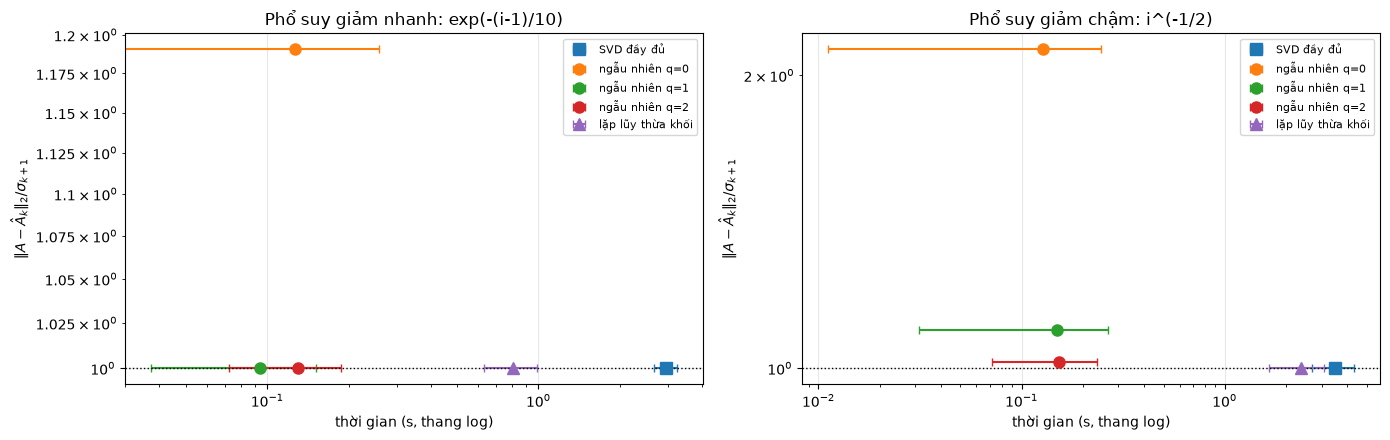

In [8]:
fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
for a_, (sname, R) in zip(ax, results_c4.items()):
    for mth, mk in zip(methods, ["s", "o", "o", "o", "^"]):
        a_.errorbar(np.mean(R[mth]["time"]), np.mean(R[mth]["spec"]), xerr=np.std(R[mth]["time"], ddof=1),
                    fmt=mk, ms=8, capsize=3, label=mth)
    a_.axhline(1, c="k", ls=":", lw=1)
    a_.set(xscale="log", yscale="log", xlabel="thời gian (s, thang log)", ylabel=r"$\|A-\hat A_k\|_2/\sigma_{k+1}$",
           title=f"Phổ suy giảm {sname}")
    a_.legend(fontsize=8)
plt.tight_layout(); plt.show()

**Nhận xét C.4.**
- **SVD đầy đủ** luôn chính xác (đạt đúng mức tối ưu Eckart–Young) nhưng chậm nhất vì tính cả 1000 thành phần dù chỉ cần 20.
- **SVD ngẫu nhiên** nhanh hơn SVD đầy đủ hàng chục lần. Với **phổ suy giảm nhanh**, $q=0$ chỉ lệch khoảng 20% so với tối ưu và $q=1$ đã đạt tối ưu (phần đuôi $\sum_{j>k}\sigma_j^2$ nhỏ). Với **phổ suy giảm chậm**, $q=0$ có sai số phổ gấp khoảng 2 lần mức tối ưu và các $\hat\sigma_i$ sai tới ~40%; cần $q=2$ vòng lặp lũy thừa mới về gần tối ưu — đúng như chặn của Halko và cộng sự (số hạng đuôi bị nâng lũy thừa $2q+1$).
- **Lặp lũy thừa khối** hội tụ nhanh với phổ suy giảm nhanh (tỉ số $(\sigma_{21}/\sigma_{20})^2=e^{-0.2}\approx0.82$ ở mỗi vòng, theo B.5) nhưng **rất chậm** với phổ suy giảm chậm ($(\sigma_{21}/\sigma_{20})^2=20/21\approx0.95$) — cần nhiều vòng hơn hẳn và vẫn kém SVD ngẫu nhiên về thời gian.
- **Ứng dụng cho Phần D:** ma trận đặc trưng rung có số chiều vừa phải nên SVD đầy đủ là đủ; SVD ngẫu nhiên/PCA tăng dần hữu ích khi dùng phổ Fourier thô (hàng nghìn chiều) hoặc giám sát trực tuyến.

---
# Tóm tắt toàn đề tài (cả 3 notebook)

| Mục | Kết quả chính |
|---|---|
| A.1 | PCA qua trị riêng và SVD trùng `sklearn`; trị riêng mất chính xác theo $\varepsilon\kappa^2$, SVD theo $\varepsilon\kappa$ |
| A.2 | SVD ngẫu nhiên đạt gần tối ưu với $q=2$; PCA tăng dần chính xác khi không cắt cụt, sai lệch không đáng kể khi $k=5$ |
| A.3 | PCA hàm nhân tuyến tính = PCA; RBF tách được dữ liệu phi tuyến. Tự mã hóa tuyến tính hội tụ về không gian con PCA, $DE=V_kV_k^\top$ |
| A.4 | $T^2$ và SPE với giới hạn $F$, Jackson–Mudholkar, Box, thực nghiệm; hai thống kê bổ sung cho nhau |
| B.1–B.6 | Chứng minh đầy đủ + kiểm chứng số từng định lý |
| C.1–C.4 | Tính tay khớp B.2; tương quan bất biến đơn vị; JL không phụ thuộc $d$; so sánh 3 thuật toán SVD |

Các lớp/hàm `pca_svd`, `randomized_svd`, `StreamingPCA`, `KernelPCA_`, `LinearAutoencoder`, `PCAMonitor`, `block_power_svd` được xuất sang `pca_core.py` để dùng trong Phần D.